# Projet 10 – Prédire l'attrition des employés (ESN)
## Étape 5 : Optimisation et interprétation du modèle

**Objectif :** régler les hyperparamètres des deux modèles retenus à l'étape 4 (régression logistique et XGBoost), choisir le modèle final, l'évaluer une seule fois sur le jeu de test, puis comprendre son comportement, globalement et pour des employés précis.

**Plan du notebook**
- **A. Fine-tuning :** recherche d'hyperparamètres (régression logistique, XGBoost), choix du modèle final, choix du seuil, évaluation finale sur le test
- **B. Interprétation :** importance globale (coefficients, Permutation Importance, SHAP) puis importance locale (Waterfall Plot)

**Métrique de réglage :** la PR-AUC (`average_precision`), qui mesure la qualité du classement des employés indépendamment du seuil. Le seuil est choisi ensuite, selon le contexte métier.

---
## 1. Chargement et séparation
Mêmes données et même découpage stratifié qu'aux étapes précédentes (fonctions de `preparation.py`), avec les trois variables créées à l'étape 4 (`ajouter_features`). Elles sont calculées ligne par ligne, donc sans fuite d'information entre le train et le test.

In [1]:
from preparation import charger_donnees, preparer_donnees, ajouter_features, separer_train_test

X, y = preparer_donnees(charger_donnees())
X = ajouter_features(X)

X_train, X_test, y_train, y_test = separer_train_test(X, y)
print(X_train.shape, X_test.shape)

(1176, 40) (294, 40)


**Contrôle :** 1 176 employés en train et 294 en test, 40 colonnes (37 + 3 variables créées).

Validation croisée stratifiée en 5 plis (mêmes plis qu'à l'étape 4).

In [2]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

---
# Partie A : Fine-tuning
## 2. Recherche d'hyperparamètres : régression logistique
Le réglage principal est `C`, l'inverse de la force de régularisation : plus `C` est petit, plus le modèle est contraint. Neuf valeurs sont testées, chacune en validation croisée à 5 plis (`GridSearchCV`).

Le `StandardScaler` est dans le `Pipeline` : il est ajusté pli par pli, sans fuite d'information.

In [3]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

grid_logreg = GridSearchCV(
    logreg,
    {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    scoring="average_precision", cv=cv, n_jobs=-1,
)
grid_logreg.fit(X_train, y_train)

print("Meilleur C :", grid_logreg.best_params_)
print("PR-AUC (CV) :", round(grid_logreg.best_score_, 4))

pd.DataFrame(grid_logreg.cv_results_)[
    ["param_logisticregression__C", "mean_test_score", "std_test_score"]
].round(3)

Meilleur C : {'logisticregression__C': 0.1}
PR-AUC (CV) : 0.6702


,param_logisticregression__C,mean_test_score,std_test_score
0,0.001,0.607,0.087
1,0.003,0.632,0.082
2,0.010,0.653,0.074
3,0.030,0.666,0.067
4,0.100,0.670,0.066
5,0.300,0.669,0.069
6,1.000,0.663,0.069
7,3.000,0.661,0.073
8,10.000,0.660,0.075


**Conclusion :** meilleur `C` = 0,1, avec une PR-AUC de **0,670**. Trop de régularisation dégrade le modèle (0,607 pour `C=0,001`). Entre 0,03 et 10, les scores se valent (0,660 à 0,670, pour un écart-type d'environ 0,07) : la régression logistique est peu sensible à ce réglage.

---
## 3. Recherche d'hyperparamètres : XGBoost
XGBoost a beaucoup d'hyperparamètres : on tire **60 combinaisons au hasard** (`RandomizedSearchCV`) plutôt que de tester une grille complète. Sont explorés :
- la taille du modèle : profondeur (`max_depth`), nombre d'arbres (`n_estimators`), vitesse d'apprentissage (`learning_rate`) ;
- la régularisation : `min_child_weight`, `gamma`, `reg_alpha`, `reg_lambda` ;
- le sous-échantillonnage : `subsample`, `colsample_bytree` ;
- la pondération des classes : `scale_pos_weight`.

*Cette cellule prend quelques minutes (300 entraînements).*

In [4]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()

param_dist = {
    "max_depth": randint(1, 5),
    "n_estimators": randint(100, 600),
    "learning_rate": loguniform(0.01, 0.2),
    "min_child_weight": randint(1, 15),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "gamma": uniform(0, 2),
    "reg_lambda": loguniform(0.5, 20),
    "reg_alpha": loguniform(0.001, 5),
    "scale_pos_weight": [1, ratio / 2, ratio],
}

search_xgb = RandomizedSearchCV(
    XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1),
    param_dist, n_iter=60, cv=cv, n_jobs=-1, random_state=42,
    scoring="average_precision",
)
search_xgb.fit(X_train, y_train)

print("Meilleurs paramètres :", search_xgb.best_params_)
print("PR-AUC (CV) :", round(search_xgb.best_score_, 4))

Meilleurs paramètres : {'colsample_bytree': np.float64(0.6326011838408627), 'gamma': np.float64(0.48797928675816715), 'learning_rate': np.float64(0.184465824705519), 'max_depth': 1, 'min_child_weight': 3, 'n_estimators': 537, 'reg_alpha': np.float64(2.24715089858035), 'reg_lambda': np.float64(2.482537616160547), 'scale_pos_weight': 1, 'subsample': np.float64(0.8010548372420768)}
PR-AUC (CV) : 0.6712


**Conclusion :** PR-AUC de **0,671**, au même niveau que la régression logistique. Les paramètres retenus décrivent un modèle très contraint : des arbres de **profondeur 1** (une seule question par arbre, donc aucun croisement entre variables), une forte régularisation et pas de pondération des classes (`scale_pos_weight=1`), ce qui confirme l'étape 4. Un XGBoost de profondeur 1 additionne des effets simples, comme le fait une régression logistique.

---
## 4. Choix du modèle final
Les deux scores sont très proches. On départage les modèles sur **25 découpages** (5 plis × 5 répétitions), différents de ceux utilisés pour les recherches.

**Règle fixée à l'avance :** à performance égale, on retient le modèle le plus simple. XGBoost n'est retenu que s'il dépasse la régression logistique d'au moins 0,02 de PR-AUC et s'il gagne sur 20 découpages sur 25 ou plus.

In [5]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)

s_logreg = cross_val_score(grid_logreg.best_estimator_, X_train, y_train,
                           cv=rcv, scoring="average_precision", n_jobs=-1)
s_xgb = cross_val_score(search_xgb.best_estimator_, X_train, y_train,
                        cv=rcv, scoring="average_precision", n_jobs=-1)

print(f"Régression logistique : {s_logreg.mean():.3f} ± {s_logreg.std():.3f}")
print(f"XGBoost               : {s_xgb.mean():.3f} ± {s_xgb.std():.3f}")

d = s_xgb - s_logreg
print(f"\nXGBoost - régression logistique : {d.mean():+.3f} | "
      f"XGBoost meilleur sur {(d > 0).sum()} découpages sur {len(d)}")

Régression logistique : 0.658 ± 0.057
XGBoost               : 0.652 ± 0.066

XGBoost - régression logistique : -0.006 | XGBoost meilleur sur 14 découpages sur 25


**Conclusion :** régression logistique 0,658 ± 0,057, XGBoost 0,652 ± 0,066. XGBoost n'est meilleur que sur 14 découpages sur 25 : les deux modèles sont à égalité. **On retient la régression logistique** (`C=0,1`), plus simple et plus facile à interpréter (un coefficient par variable).

Les scores sont un peu plus bas que ceux des recherches (0,670 et 0,671) : c'est attendu, les hyperparamètres ayant été choisis sur les plis précédents.

---
## 5. Choix du seuil de décision
Les probabilités du train sont calculées **en validation croisée** (`cross_val_predict`) : chaque employé est prédit par un modèle qui ne l'a jamais vu. On compare ensuite plusieurs seuils.

Sans pondération des classes, ce sont de vraies probabilités : un seuil de 0,20 signifie « au moins 20 % de risque de départ ».

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score, f1_score

modele = grid_logreg.best_estimator_

proba = cross_val_predict(modele, X_train, y_train, cv=cv,
                          method="predict_proba")[:, 1]

print("seuil | recall | precision | f1 | fausses alertes par départ trouvé")
for seuil in [0.10, 0.15, 0.18, 0.20, 0.22, 0.25, 0.30, 0.40, 0.50]:
    pred = (proba >= seuil).astype(int)
    r, p = recall_score(y_train, pred), precision_score(y_train, pred)
    print(f"{seuil:.2f}  | {r:.2f}   | {p:.2f}      | {f1_score(y_train, pred):.2f} | {(1-p)/p:.1f}")

seuil | recall | precision | f1 | fausses alertes par départ trouvé
0.10  | 0.85   | 0.31      | 0.45 | 2.3
0.15  | 0.79   | 0.37      | 0.50 | 1.7
0.18  | 0.74   | 0.39      | 0.51 | 1.5
0.20  | 0.73   | 0.45      | 0.55 | 1.2
0.22  | 0.68   | 0.46      | 0.55 | 1.2
0.25  | 0.67   | 0.50      | 0.57 | 1.0
0.30  | 0.64   | 0.58      | 0.60 | 0.7
0.40  | 0.53   | 0.72      | 0.61 | 0.4
0.50  | 0.39   | 0.83      | 0.54 | 0.2


**Seuil retenu : 0,20** (recall 0,73, precision 0,45 en validation croisée, soit environ 1,2 fausse alerte par départ trouvé).

*Justification métier :* un départ non détecté (recrutement, formation, perte de savoir-faire) coûte plus cher qu'une fausse alerte (entretien, geste de rétention). On vise donc un recall proche de 0,75.
- Entre 0,18 et 0,20, on perd 1 point de recall pour 6 points de precision gagnés.
- Au-dessus de 0,22, le recall passe sous 0,70 : trop de départs ratés.
- À 0,15, le recall monte à 0,79, mais avec 1,7 fausse alerte par départ trouvé.

---
## 6. Évaluation finale sur le jeu de test
Le modèle (`grid_logreg.best_estimator_`, déjà réentraîné sur tout le train) et le seuil sont fixés avant de regarder le test, utilisé une seule fois.

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

SEUIL = 0.20

proba_test = modele.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)

print(classification_report(y_test, pred_test, zero_division=0))
print(confusion_matrix(y_test, pred_test))

              precision    recall  f1-score   support

           0       0.93      0.84      0.88       247
           1       0.44      0.66      0.53        47

    accuracy                           0.81       294
   macro avg       0.68      0.75      0.70       294
weighted avg       0.85      0.81      0.82       294

[[207  40]
 [ 16  31]]


**Conclusion :**

| | prédit « resté » | prédit « parti » |
|---|---|---|
| **vrai resté** (247) | 207 | 40 (fausses alertes) |
| **vrai parti** (47) | 16 (partis ratés) | 31 (partis retrouvés) |

- **Recall = 0,66** : 31 des 47 partis sont retrouvés (le Dummy n'en retrouve aucun).
- **Precision = 0,44** : sur 71 alertes, 31 sont justes, soit environ 1,3 fausse alerte par départ trouvé. F1 = 0,53.
- **Comparaison avec la validation croisée** (0,73 / 0,45) : la precision est conforme ; le recall est plus bas, de 3 employés. Avec 47 partis, l'incertitude sur le recall est d'environ ± 0,07 : l'écart reste dans cette marge. Le seuil n'est pas modifié après coup.
- **Usage :** en ciblant 71 employés sur 294 (24 %), on retrouve 2 départs sur 3.

---
# Partie B : Interprétation du modèle
## 7. Importance globale des variables
Trois méthodes sont comparées : les coefficients du modèle, la Permutation Importance et SHAP.

### 7.1 Coefficients de la régression logistique
C'est l'importance « native » d'un modèle linéaire. Les variables étant standardisées, les coefficients sont comparables entre eux :
- coefficient **positif** (rouge) : la variable pousse vers le départ ;
- coefficient **négatif** (bleu) : elle pousse vers « resté » ;
- plus la barre est longue, plus l'effet est fort.

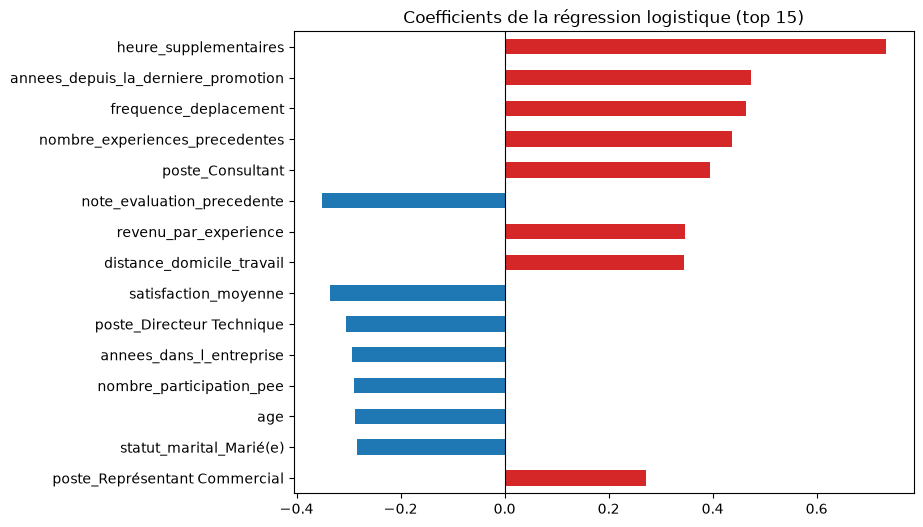

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

coefs = pd.Series(modele.named_steps["logisticregression"].coef_[0],
                  index=X_train.columns)

top = coefs.abs().sort_values().tail(15).index
coefs[top].plot(kind="barh", figsize=(8, 6),
                color=["tab:red" if v > 0 else "tab:blue" for v in coefs[top]])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coefficients de la régression logistique (top 15)")
plt.show()

**Conclusion :** `heure_supplementaires` a de loin le coefficient le plus fort (+0,73).
- **Poussent vers le départ :** les années depuis la dernière promotion, la fréquence de déplacement, le nombre d'expériences précédentes, les postes de consultant et de représentant commercial, la distance domicile-travail.
- **Retiennent l'employé :** une bonne note d'évaluation précédente, une satisfaction moyenne élevée, le poste de directeur technique, l'ancienneté, la participation au PEE, l'âge et le fait d'être marié.

Deux précautions de lecture :
- Un coefficient se lit « toutes choses égales par ailleurs ». Quand des variables sont corrélées (âge, expérience, ancienneté, revenu), l'effet est réparti entre elles : `revenu_mensuel` n'apparaît pas dans ce top 15 alors qu'il ressortait à l'exploration.
- `revenu_par_experience` a un coefficient positif : ce rapport est surtout élevé quand l'expérience est faible. Il signale donc probablement les profils juniors, et non des employés « trop payés ».

### 7.2 Permutation Importance
On mélange au hasard les valeurs d'une colonne et on mesure la baisse de la PR-AUC sur le test (20 répétitions) : plus la baisse est forte, plus le modèle dépend de cette colonne. Cette méthode ne donne pas le sens de l'effet.

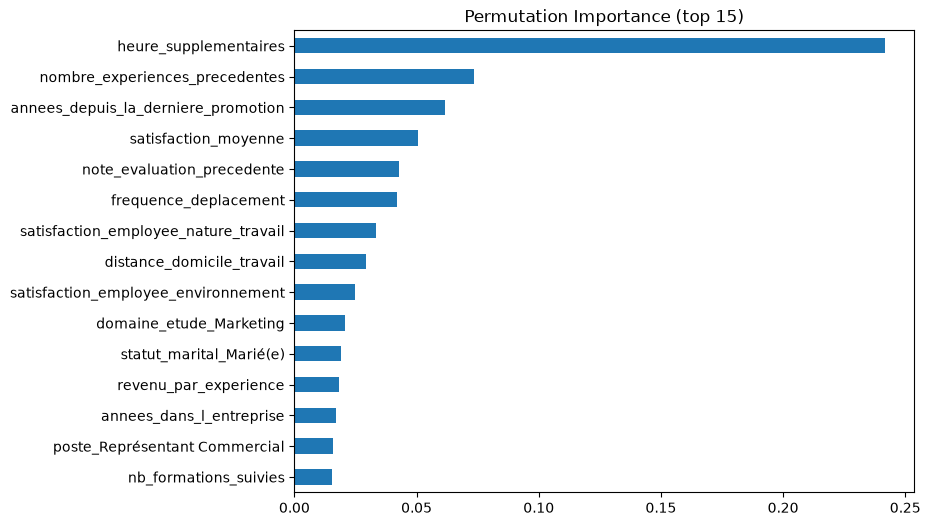

In [9]:
from sklearn.inspection import permutation_importance

resultat = permutation_importance(
    modele, X_test, y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importances_perm = pd.Series(resultat.importances_mean, index=X_test.columns)

importances_perm.sort_values().tail(15).plot(kind="barh", figsize=(8, 6))
plt.title("Permutation Importance (top 15)")
plt.show()

**Conclusion :** `heure_supplementaires` domine nettement (baisse de PR-AUC ≈ 0,24), loin devant `nombre_experiences_precedentes` (≈ 0,07), `annees_depuis_la_derniere_promotion` (≈ 0,06), `satisfaction_moyenne` (≈ 0,05), `note_evaluation_precedente` et `frequence_deplacement` (≈ 0,04). Les barres suivantes sont petites et peu fiables (test de 47 partis).

`satisfaction_moyenne`, créée à l'étape 4, arrive en 4e position : le modèle s'en sert réellement.

### 7.3 SHAP : beeswarm
SHAP calcule, pour chaque employé, la contribution de chaque variable à sa **probabilité de départ** (une valeur de +0,10 ajoute 10 points de risque). La référence est un échantillon de 100 employés du train.

Lecture : chaque point est un employé du test. Position horizontale : impact sur la prédiction (à droite : vers « parti » ; à gauche : vers « resté »). Couleur : valeur de la variable (rouge = élevée, bleu = basse).

PermutationExplainer explainer: 295it [00:12,  5.16it/s]                         


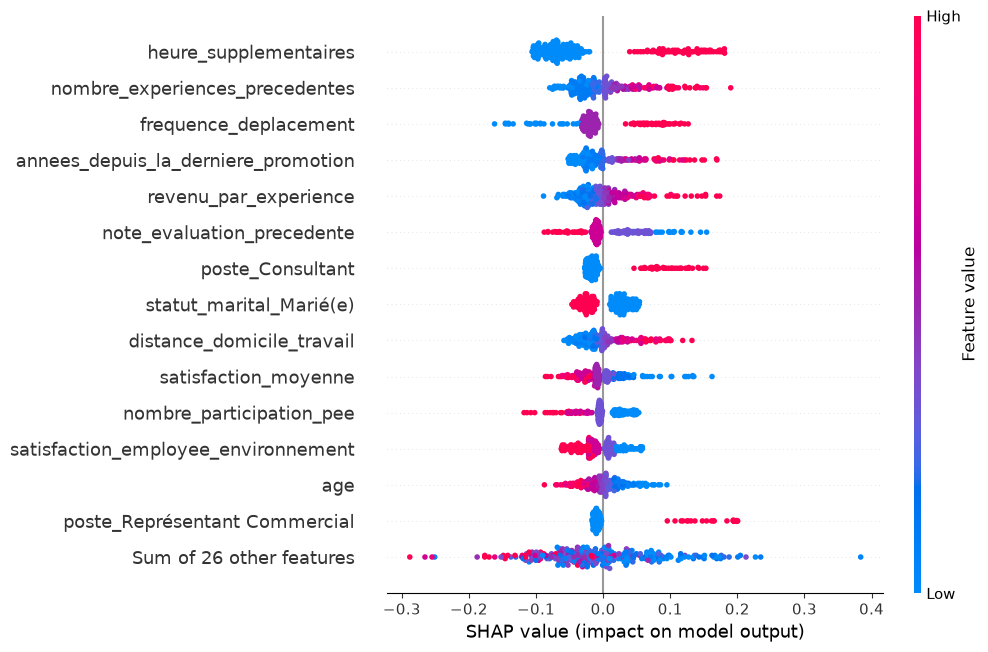

In [10]:
import shap

def proba_depart(donnees):
    donnees = pd.DataFrame(donnees, columns=X_train.columns)
    return modele.predict_proba(donnees)[:, 1]

fond = shap.sample(X_train, 100, random_state=42)

explainer = shap.Explainer(proba_depart, fond)
shap_values = explainer(X_test)

shap.plots.beeswarm(shap_values, max_display=15)

**Conclusion :** SHAP confirme le **sens** des effets et donne leur taille, en points de probabilité.
- **Heures supplémentaires :** +4 à +18 points de risque pour ceux qui en font, −3 à −10 points pour les autres. C'est l'effet le plus fort et le plus répandu.
- **Poussent aussi vers le départ :** de nombreuses expériences précédentes, des déplacements fréquents, une longue période sans promotion, un `revenu_par_experience` élevé (profils juniors), un long trajet, et les postes de consultant (+5 à +15 points) et de représentant commercial (+9 à +20 points, mais peu d'employés concernés).
- **Retiennent l'employé :** une bonne note d'évaluation, le fait d'être marié, une satisfaction élevée, la participation au PEE et l'âge.

Ces liens sont des corrélations exploitées par le modèle, pas des relations de cause à effet.

### 7.4 Comparaison des méthodes d'importance globale
Les 8 premières variables selon chaque méthode (coefficients en valeur absolue, baisse de PR-AUC, moyenne des valeurs SHAP en valeur absolue).

In [11]:
import numpy as np

def top8(serie):
    return serie.sort_values(ascending=False).head(8).index.to_list()

shap_moyen = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test.columns)

pd.DataFrame({
    "Coefficients": top8(coefs.abs()),
    "Permutation Importance": top8(importances_perm),
    "SHAP": top8(shap_moyen),
}, index=range(1, 9))

,Coefficients,Permutation Importance,SHAP
1,heure_supplementaires,heure_supplementaires,heure_supplementaires
2,annees_depuis_la_derniere_promotion,nombre_experiences_precedentes,nombre_experiences_precedentes
3,frequence_deplacement,annees_depuis_la_derniere_promotion,frequence_deplacement
4,nombre_experiences_precedentes,satisfaction_moyenne,annees_depuis_la_derniere_promotion
5,poste_Consultant,note_evaluation_precedente,revenu_par_experience
6,note_evaluation_precedente,frequence_deplacement,note_evaluation_precedente
7,revenu_par_experience,satisfaction_employee_nature_travail,poste_Consultant
8,distance_domicile_travail,distance_domicile_travail,statut_marital_Marié(e)


**Conclusion :**

**Convergences :** `heure_supplementaires` est première dans les trois méthodes. Quatre autres variables sont dans le top 8 des trois : `nombre_experiences_precedentes`, `annees_depuis_la_derniere_promotion`, `frequence_deplacement` et `note_evaluation_precedente`.

**Divergences :**
- `poste_Consultant` et `revenu_par_experience` ressortent avec les coefficients et SHAP, mais pas en permutation : cette méthode est sévère avec les variables redondantes (quand on en mélange une, le modèle retrouve une partie de l'information dans les autres).
- `satisfaction_moyenne` et `satisfaction_employee_nature_travail` ne sont dans le top 8 qu'en permutation.
- Les coefficients et SHAP donnent des classements très proches : c'est attendu, car pour un modèle linéaire les valeurs SHAP découlent directement des coefficients.

**Apport de SHAP :** il exprime chaque effet en points de probabilité et permet de passer du global (toutes les variables) au local (un employé).

### 7.5 Comprendre les valeurs SHAP : `shap.plots.scatter`
Effet d'une variable (ici le revenu) sur la prédiction en fonction de sa valeur ; la couleur indique une seconde variable (ici l'âge).

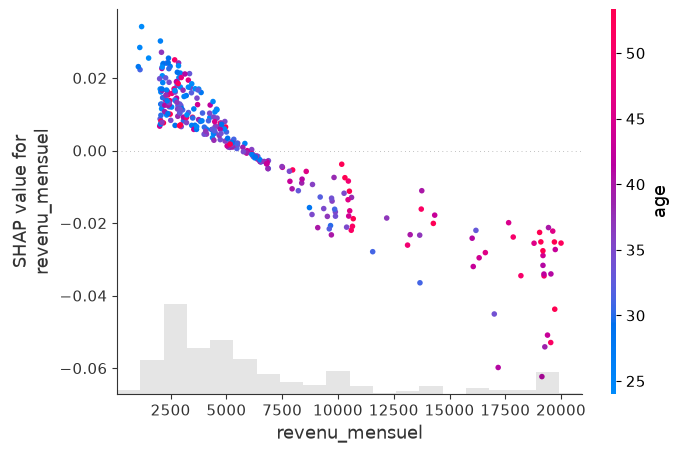

In [12]:
shap.plots.scatter(
    shap_values[:, "revenu_mensuel"],
    color=shap_values[:, "age"]
)

**Conclusion :** l'effet du revenu est **régulier et décroissant** : sous environ 5 000 €, il augmente légèrement le risque (jusqu'à +3 points vers 1 500 €) ; au-delà, il le réduit (jusqu'à −6 points vers 19 000 €).

- L'effet direct du revenu est **faible** (quelques points) face aux heures supplémentaires (jusqu'à +18 points). Dans ce modèle, l'information du revenu passe surtout par `revenu_par_experience`, le poste et l'ancienneté.
- Il n'y a **pas d'effet de seuil** : une régression logistique ne peut représenter qu'un effet progressif.
- Les bas revenus sont surtout ceux des plus jeunes (points bleus), les hauts revenus ceux des plus âgés (points rouges).

---
## 8. Importance locale : Waterfall Plot
Il explique la prédiction pour **un seul employé** : on part de la probabilité moyenne `E[f(X)]` et chaque barre ajoute ou retire de la probabilité de départ, jusqu'à `f(x)`, la probabilité de cet employé. Rouge : pousse vers « parti » ; bleu : vers « resté ».

Deux cas francs sont expliqués : le parti le mieux repéré et le resté le plus sûr.

Parti le mieux repéré, probabilité : 0.96


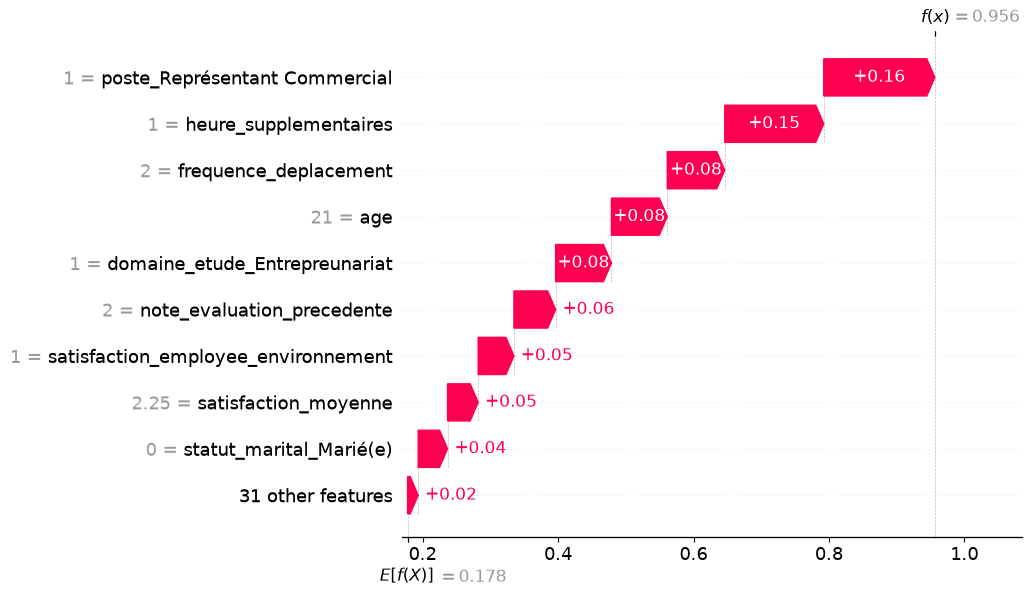

Resté le plus sûr, probabilité : 0.0


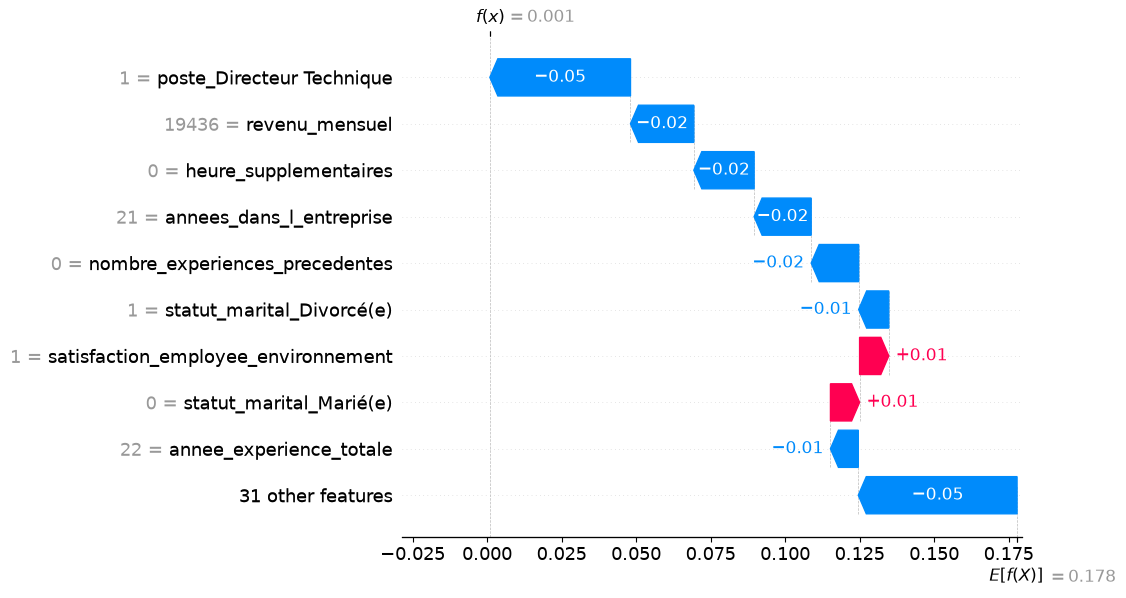

In [13]:
y_arr = y_test.to_numpy()

idx_parti_sur = np.nanargmax(np.where(y_arr == 1, proba_test, np.nan))
idx_reste_sur = np.nanargmin(np.where(y_arr == 0, proba_test, np.nan))

print("Parti le mieux repéré, probabilité :", proba_test[idx_parti_sur].round(2))
shap.plots.waterfall(shap_values[idx_parti_sur])

print("Resté le plus sûr, probabilité :", proba_test[idx_reste_sur].round(2))
shap.plots.waterfall(shap_values[idx_reste_sur])

**Conclusion :** la probabilité moyenne de départ est `E[f(X)]` = 0,18, proche du taux de départ réel (16 %).
- **Parti le mieux repéré (f(x) = 0,96) :** représentant commercial (+0,16), heures supplémentaires (+0,15), déplacements fréquents (+0,08), 21 ans (+0,08), note d'évaluation précédente de 2 (+0,06), faible satisfaction (+0,05). **Toutes les barres poussent vers le départ.**
- **Resté le plus sûr (f(x) = 0,001) :** directeur technique (−0,05), revenu de 19 436 €, pas d'heures supplémentaires, 21 ans d'ancienneté, aucune expérience précédente. Presque toutes les barres poussent vers « resté ». Elles sont petites parce que la probabilité ne peut pas descendre sous 0.

Le modèle est sûr de lui sur les profils **typiques**. Ses erreurs viennent des profils mélangés et des raisons personnelles de départ, absentes des données.

---
## 9. Synthèse de l'étape 5
- **Modèle final :** régression logistique (`C=0,1`, variables standardisées, 40 colonnes dont 3 créées), seuil de décision 0,20.
- **Choix du modèle :** à égalité avec un XGBoost optimisé (PR-AUC 0,658 contre 0,652 sur 25 découpages), on retient le plus simple.
- **Performance (test) :** recall 0,66 (31 départs retrouvés sur 47), precision 0,44 (40 fausses alertes sur 247 restés), F1 0,53.
- **Facteurs principaux :** les heures supplémentaires, de loin ; puis le nombre d'expériences précédentes, les années depuis la dernière promotion, la fréquence de déplacement et la note d'évaluation précédente ; les postes de consultant et de représentant commercial. Facteurs protecteurs : satisfaction, ancienneté, participation au PEE, âge, être marié.
- **Convergence des méthodes :** `heure_supplementaires` est première partout ; cinq variables sont dans le top 8 des coefficients, de la Permutation Importance et de SHAP.
- **Usage métier :** l'outil sert à **prioriser** (cibler 71 employés sur 294 pour retrouver 2 départs sur 3), pas à prédire avec certitude.
- **Limites :** seulement 47 départs dans le test (scores instables), corrélations et non causalités, raisons personnelles de départ absentes des données.